### Notebook 07: Perbandingan Model dan Registry

#### 1. Persiapan

##### 1.1 Pustaka

In [1]:
import importlib
import json
import platform
import sys
import time
import warnings
from datetime import datetime
from pathlib import Path

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import sklearn
from sklearn.exceptions import ConvergenceWarning

print("Python       :", platform.python_version())
print("NumPy        :", np.__version__)
print("pandas       :", pd.__version__)
print("scikit-learn :", sklearn.__version__)
print("matplotlib   :", matplotlib.__version__)

Python       : 3.10.6
NumPy        : 1.26.4
pandas       : 2.2.3
scikit-learn : 1.5.2
matplotlib   : 3.9.2


##### 1.2 Konfigurasi

In [2]:
def find_ml_dir(start: Path) -> Path:
    for folder in [start, *start.parents]:
        if (folder / "src" / "registry.py").exists():
            return folder
        if (folder / "ml" / "src" / "registry.py").exists():
            return folder / "ml"
    raise FileNotFoundError("Folder ml/ tidak ditemukan. Buka notebook ini dari dalam repo Nutrify.")


ML_DIR = find_ml_dir(Path.cwd().resolve())
if str(ML_DIR) not in sys.path:
    sys.path.insert(0, str(ML_DIR))

from src import c45, evaluation as ev, models, registry

for module in (c45, ev, models, registry):
    importlib.reload(module)

PREFIX = "07"
SEED = 42
N_BOOTSTRAP = 2000
GALLERY_SIZE = 12
SVM_MAX_ITER = 5_000_000
MODEL_VERSION = "0.1.0"

PRIMARY_MODEL = "C4.5"
MACRO_F1_MARGIN = 0.05
MIN_DEFICIENCY_RECALL = 0.70
THRESHOLDS_CONFIRMED_WITH_SUPERVISOR = False

MODEL_NAMES = ("C4.5", "SVM", "Naive Bayes", "Random Forest")
MODEL_IDS = {"C4.5": "c45", "SVM": "svm", "Naive Bayes": "naive-bayes", "Random Forest": "random-forest"}
RESULT_FILES = {"C4.5": "03_c45_results.json", "SVM": "04_svm_results.json", "Naive Bayes": "05_naive_bayes_results.json", "Random Forest": "06_random_forest_results.json"}
MODEL_COLORS = ev.MODEL_COLORS

RAW_DIR = ML_DIR / "data" / "raw"
PROCESSED_DIR = ML_DIR / "data" / "processed"
FIGURES_DIR = ML_DIR / "reports" / "figures"
TABLES_DIR = ML_DIR / "reports" / "tables"
RESULTS_DIR = ML_DIR / "reports" / "results"
MODELS_DIR = ML_DIR / "models"
for folder in (FIGURES_DIR, TABLES_DIR, RESULTS_DIR, MODELS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

CLASSES = ev.CLASSES
CLASS_LABEL_ID = ev.CLASS_LABEL_ID
CLASS_COLORS = ev.CLASS_COLORS
rng = np.random.default_rng(SEED)

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.spines.top": False, "axes.spines.right": False})


def save_figure(fig, name: str) -> None:
    fig.savefig(FIGURES_DIR / f"{PREFIX}_{name}", bbox_inches="tight")


def save_table(table, name: str, **kwargs) -> None:
    table.to_csv(TABLES_DIR / f"{PREFIX}_{name}.csv", **kwargs)


def as_float(value):
    return None if value is None or (isinstance(value, float) and np.isnan(value)) else float(value)


print("Folder ml/ :", ML_DIR)

Folder ml/ : D:\LARAGON\www\nutrify\ml


##### 1.3 Perangkat keras

In [3]:
HARDWARE = {
    "Laptop": "Lenovo LOQ 15IAX9",
    "CPU": "Intel Core i5-12450HX, 2.40 GHz",
    "RAM": "12 GB DDR5 (11,7 GB dapat dipakai)",
    "GPU": "Tidak dipakai (RTX 3050 tersedia, scikit-learn berjalan di CPU)",
    "Sistem": "Windows 11 Home, 64-bit",
}
hardware_table = pd.Series(
    {**HARDWARE, "Python": platform.python_version(), "Inti logis CPU": psutil.cpu_count(logical=True), "RAM terdeteksi (GB)": round(psutil.virtual_memory().total / 1024 ** 3, 1)},
    name="nilai",
).to_frame()
display(hardware_table)

,nilai
Laptop,Lenovo LOQ 15IAX9
CPU,"Intel Core i5-12450HX, 2.40 GHz"
RAM,"12 GB DDR5 (11,7 GB dapat dipakai)"
GPU,"Tidak dipakai (RTX 3050 tersedia, scikit-learn..."
Sistem,"Windows 11 Home, 64-bit"
Python,3.10.6
Inti logis CPU,12
RAM terdeteksi (GB),11.7


#### 2. Hasil Terkunci dari Notebook 03 sampai 06

##### 2.1 Parameter dan himpunan fitur

In [4]:
results = {name: json.loads((RESULTS_DIR / file).read_text(encoding="utf-8")) for name, file in RESULT_FILES.items()}


def locked_setting(name):
    r = results[name]
    if name == "C4.5":
        return {"features": r["selected"]["features"], "feature_set": r["selected"]["feature_set"], "params": r["selected"]["params"], "class_weight": r["data"]["class_weight"]}
    return {"features": r["feature_set"]["features"], "feature_set": r["feature_set"]["selected"], "params": r["selected"]["params"], "class_weight": None}


locked = {name: locked_setting(name) for name in MODEL_NAMES}
FEATURES = locked[PRIMARY_MODEL]["features"]
SELECTED_SET = locked[PRIMARY_MODEL]["feature_set"]
assert all(setting["features"] == FEATURES for setting in locked.values()), "Himpunan fitur antar model berbeda"

locked_table = pd.DataFrame(
    {
        name: {
            "himpunan fitur": locked[name]["feature_set"],
            "parameter": str(locked[name]["params"]),
            "F1 makro validasi": results[name]["selected"]["oof_metrics"]["macro_f1_fold_mean"],
            "SD lipatan": results[name]["selected"]["oof_metrics"]["macro_f1_fold_sd"],
        }
        for name in MODEL_NAMES
    }
).T
save_table(locked_table, "locked_settings")
display(locked_table)

,himpunan fitur,parameter,F1 makro validasi,SD lipatan
C4.5,A1,"{'max_depth': 3, 'min_samples_leaf': 10, 'conf...",0.6988,0.080413
SVM,A1,"{'kernel': 'rbf', 'C': 100, 'gamma': 0.1}",0.762266,0.092614
Naive Bayes,A1,{'var_smoothing': 0.001},0.596007,0.062139
Random Forest,A1,"{'n_estimators': 500, 'max_depth': 5, 'min_sam...",0.722453,0.086387


##### 2.2 Data latih, uji, dan eksternal

In [5]:
train = ev.load_partition(ML_DIR, "train")
test = ev.load_partition(ML_DIR, "test")
external = ev.load_partition(ML_DIR, "external")

overlap = set(train["source_group"]) & set(test["source_group"])
assert not overlap, f"Kebocoran foto sumber: {sorted(overlap)[:5]}"

partition_table = pd.DataFrame(
    {
        "latih": train.groupby("label").size(),
        "uji": test.groupby("label").size(),
        "eksternal": external.groupby("label").size(),
    }
).reindex(CLASSES).fillna(0).astype(int)
partition_table.index = [CLASS_LABEL_ID[c] for c in partition_table.index]
partition_table.loc["Total"] = partition_table.sum()
group_table = pd.DataFrame({"foto sumber latih": [train["source_group"].nunique()], "foto sumber uji": [test["source_group"].nunique()], "irisan": [len(overlap)]})
save_table(partition_table, "partition_summary")
display(partition_table)
display(group_table)

,latih,uji,eksternal
Normal,92,20,8
Defisiensi N,70,22,0
Defisiensi Fe,142,34,0
Total,304,76,8


,foto sumber latih,foto sumber uji,irisan
0,108,28,0


##### 2.3 Catatan akses data uji

In [6]:
access_log_path = RESULTS_DIR / "07_test_access_log.csv"
locked_signature = json.dumps({name: locked[name]["params"] for name in MODEL_NAMES}, sort_keys=True, default=str)
entry = pd.DataFrame([{"waktu": datetime.now().isoformat(timespec="seconds"), "berkas_uji": len(test), "tanda_parameter": pd.util.hash_pandas_object(pd.Series([locked_signature])).iloc[0]}])
log = pd.concat([pd.read_csv(access_log_path), entry], ignore_index=True) if access_log_path.exists() else entry
log.to_csv(access_log_path, index=False)
display(log)

,waktu,berkas_uji,tanda_parameter
0,2026-11-21T18:42:30,76,2702938658228192326


#### 3. Landasan Evaluasi

##### 3.1 Metrik klasifikasi

$$
P_c = \frac{TP_c}{TP_c + FP_c}, \qquad R_c = \frac{TP_c}{TP_c + FN_c}, \qquad F1_c = \frac{2 P_c R_c}{P_c + R_c}, \qquad F1_{\text{makro}} = \frac{1}{K}\sum_{c=1}^{K} F1_c
$$

$$
\text{akurasi} = \frac{\sum_c TP_c}{n}
$$

##### 3.2 Interval kepercayaan bootstrap per foto sumber

$$
\hat{\theta}^{*(b)} = \theta\left(\{g_1^{*}, \dots, g_G^{*}\}\right), \qquad \mathrm{CI}_{95\%} = \left[\hat{\theta}^{*}_{0{,}025},\ \hat{\theta}^{*}_{0{,}975}\right]
$$

##### 3.3 Selisih berpasangan antar model

$$
\Delta^{*(b)} = \theta_A\left(\{g_i^{*}\}\right) - \theta_B\left(\{g_i^{*}\}\right)
$$

dengan himpunan foto sumber $\{g_i^{*}\}$ yang sama untuk kedua model pada setiap pengulangan $b$.

##### 3.4 Aturan pemilihan model utama

$$
\max_m F1_{\text{makro}}^{(m)} - F1_{\text{makro}}^{(\text{C4.5})} \le 0{,}05, \qquad R_{N}^{(\text{C4.5})} \ge 0{,}70, \qquad R_{Fe}^{(\text{C4.5})} \ge 0{,}70
$$

##### 3.5 Kurva ROC dan Precision-Recall

$$
\mathrm{TPR} = \frac{TP}{TP + FN}, \qquad \mathrm{FPR} = \frac{FP}{FP + TN}, \qquad \mathrm{AP} = \sum_{n} (R_n - R_{n-1})\, P_n
$$

#### 4. Pelatihan Ulang dengan Parameter Terkunci

##### 4.1 Pelatihan pada seluruh data latih

In [7]:
BUILDERS = {
    "C4.5": lambda: c45.C45Classifier(class_weight=locked["C4.5"]["class_weight"], **locked["C4.5"]["params"]),
    "SVM": lambda: models.svm_model(locked["SVM"]["params"], max_iter=SVM_MAX_ITER),
    "Naive Bayes": lambda: models.naive_bayes_model(locked["Naive Bayes"]["params"]),
    "Random Forest": lambda: models.random_forest_model(locked["Random Forest"]["params"]),
}

X_train = train[FEATURES].to_numpy(dtype=float)
y_train = train["label"].to_numpy()

fitted, fit_seconds = {}, {}
for name in MODEL_NAMES:
    started = time.perf_counter()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        fitted[name] = BUILDERS[name]().fit(X_train, y_train, FEATURES, CLASSES)
    fit_seconds[name] = time.perf_counter() - started
    print(f"{name:14s} dilatih dalam {fit_seconds[name]:.3f} detik")

C4.5           dilatih dalam 0.009 detik
SVM            dilatih dalam 0.008 detik
Naive Bayes    dilatih dalam 0.002 detik
Random Forest  dilatih dalam 0.434 detik


##### 4.2 Kesesuaian pohon C4.5 dengan kandidat notebook 03

In [8]:
candidate = json.loads((MODELS_DIR / "candidates" / "c45_candidate.json").read_text(encoding="utf-8"))
retrained_payload = json.loads(json.dumps(fitted["C4.5"].to_dict(version=f"c45-{MODEL_VERSION}")))
same_tree = retrained_payload["tree"] == candidate["tree"]
print("Pohon hasil pelatihan ulang sama dengan kandidat notebook 03 :", same_tree)
assert same_tree

Pohon hasil pelatihan ulang sama dengan kandidat notebook 03 : True


#### 5. Evaluasi pada Data Uji

##### 5.1 Prediksi

In [9]:
def predict_frame(model, frame):
    X = frame[FEATURES].to_numpy(dtype=float)
    scores = ev.score_matrix(model, X)
    out = frame[["image_id", "source_group", "label", "folder"]].copy().reset_index(drop=True)
    out["pred"] = model.predict(X)
    for i, c in enumerate(CLASSES):
        out[f"score_{c}"] = scores[:, i]
    return out


test_predictions = {name: predict_frame(fitted[name], test) for name in MODEL_NAMES}
pd.concat({name: frame for name, frame in test_predictions.items()}, names=["model"]).reset_index(level=0).to_csv(RESULTS_DIR / "07_test_predictions.csv", index=False)
print("Berkas uji :", len(test), "| foto sumber :", test["source_group"].nunique())

Berkas uji : 76 | foto sumber : 28


##### 5.2 Metrik utama semua model

In [10]:
summary_rows, per_class_rows = {}, []
for name, frame in test_predictions.items():
    table = ev.metrics_table(frame["label"], frame["pred"])
    summary_rows[name] = {
        "akurasi": table.loc["Akurasi", "f1"],
        "F1 makro": table.loc["Rata-rata makro", "f1"],
        "precision makro": table.loc["Rata-rata makro", "precision"],
        "recall makro": table.loc["Rata-rata makro", "recall"],
        **{f"recall {CLASS_LABEL_ID[c]}": table.loc[CLASS_LABEL_ID[c], "recall"] for c in CLASSES},
        **{f"F1 {CLASS_LABEL_ID[c]}": table.loc[CLASS_LABEL_ID[c], "f1"] for c in CLASSES},
    }
    per_class_rows.append(table.loc[[CLASS_LABEL_ID[c] for c in CLASSES]].assign(model=name))

test_summary = pd.DataFrame(summary_rows).T
per_class_long = pd.concat(per_class_rows).reset_index(names="kelas")[["model", "kelas", "precision", "recall", "f1", "support"]]
save_table(test_summary.round(4), "test_summary")
save_table(per_class_long.round(4), "test_per_class", index=False)
display(test_summary.round(4))
display(per_class_long.round(4))

,akurasi,F1 makro,precision makro,recall makro,recall Normal,recall Defisiensi N,recall Defisiensi Fe,F1 Normal,F1 Defisiensi N,F1 Defisiensi Fe
C4.5,0.7237,0.7035,0.8342,0.6758,0.45,0.6364,0.9412,0.6207,0.7368,0.7529
SVM,0.8421,0.8431,0.8589,0.8381,0.95,0.6818,0.8824,0.9268,0.7692,0.8333
Naive Bayes,0.6316,0.6363,0.6345,0.6660,0.80,0.7273,0.4706,0.6809,0.6667,0.5614
Random Forest,0.8158,0.8156,0.8699,0.7910,0.75,0.6818,0.9412,0.8571,0.7692,0.8205


,model,kelas,precision,recall,f1,support
0,C4.5,Normal,1.0000,0.4500,0.6207,20.0
1,C4.5,Defisiensi N,0.8750,0.6364,0.7368,22.0
2,C4.5,Defisiensi Fe,0.6275,0.9412,0.7529,34.0
3,SVM,Normal,0.9048,0.9500,0.9268,20.0
4,SVM,Defisiensi N,0.8824,0.6818,0.7692,22.0
5,SVM,Defisiensi Fe,0.7895,0.8824,0.8333,34.0
6,Naive Bayes,Normal,0.5926,0.8000,0.6809,20.0
7,Naive Bayes,Defisiensi N,0.6154,0.7273,0.6667,22.0
8,Naive Bayes,Defisiensi Fe,0.6957,0.4706,0.5614,34.0
9,Random Forest,Normal,1.0000,0.7500,0.8571,20.0


##### 5.3 Skor validasi silang dan skor uji

In [11]:
gap_table = pd.DataFrame(
    {
        "F1 makro validasi silang": {n: results[n]["selected"]["oof_metrics"]["macro_f1_fold_mean"] for n in MODEL_NAMES},
        "SD lipatan": {n: results[n]["selected"]["oof_metrics"]["macro_f1_fold_sd"] for n in MODEL_NAMES},
        "F1 makro uji": {n: test_summary.loc[n, "F1 makro"] for n in MODEL_NAMES},
    }
)
gap_table["selisih (uji - validasi)"] = gap_table["F1 makro uji"] - gap_table["F1 makro validasi silang"]
save_table(gap_table.round(4), "cv_vs_test")
display(gap_table.round(4))

,F1 makro validasi silang,SD lipatan,F1 makro uji,selisih (uji - validasi)
C4.5,0.6988,0.0804,0.7035,0.0047
SVM,0.7623,0.0926,0.8431,0.0809
Naive Bayes,0.5960,0.0621,0.6363,0.0403
Random Forest,0.7225,0.0864,0.8156,0.0932


##### 5.4 Matriks konfusi semua model

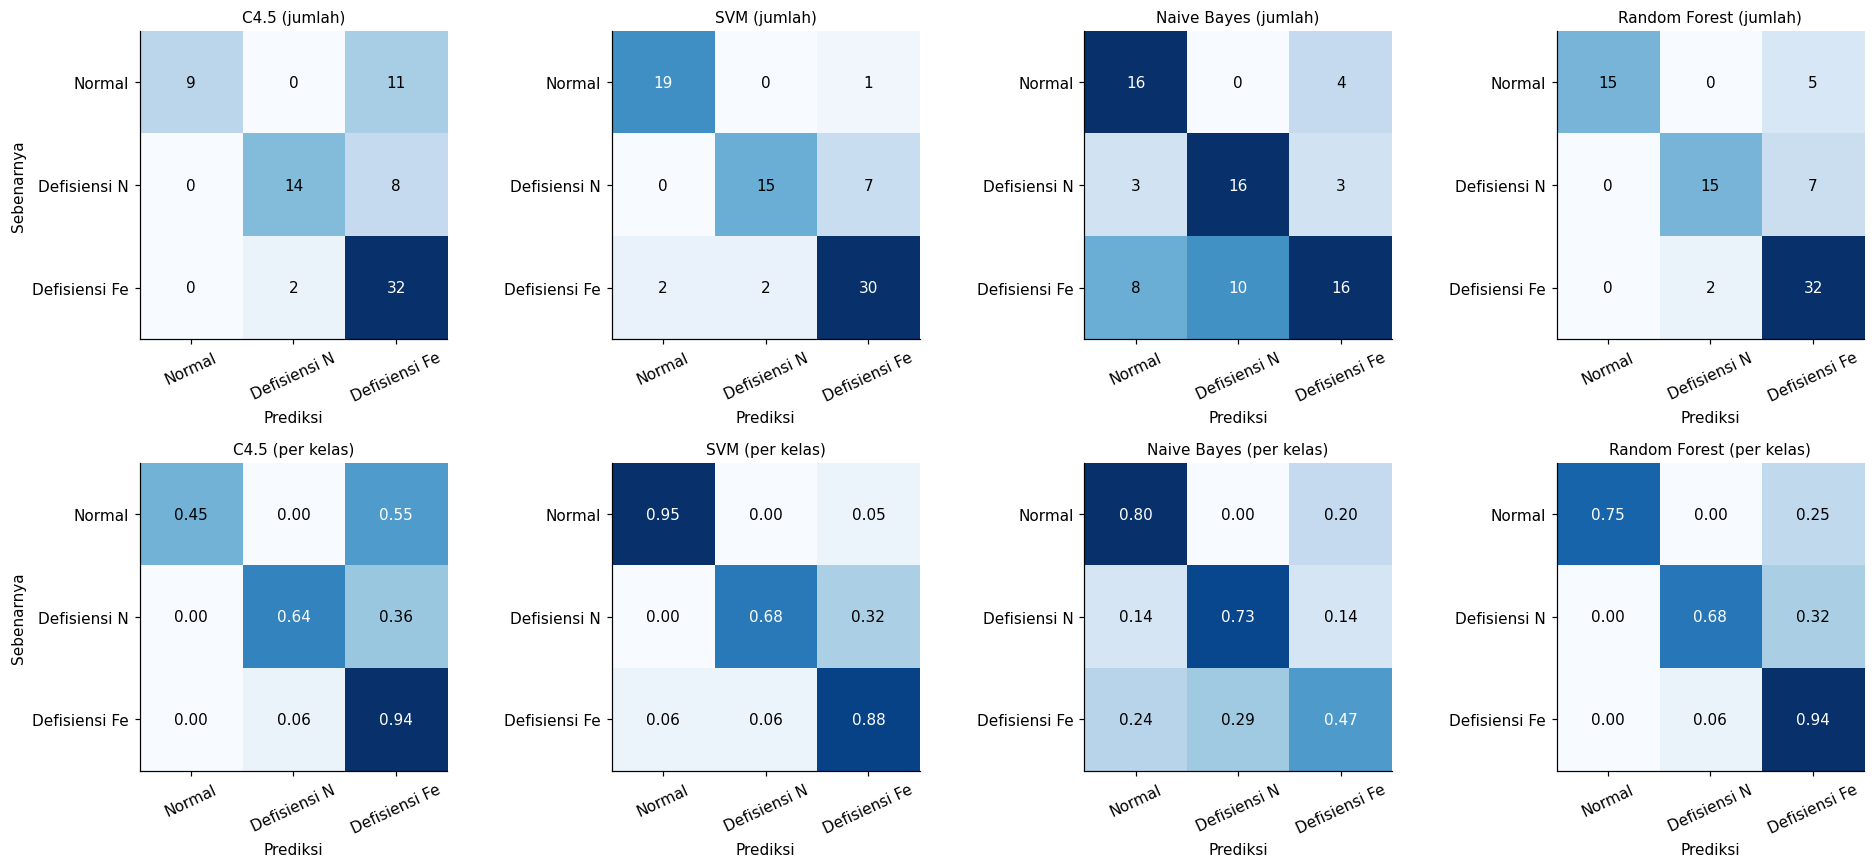

In [12]:
fig, axes = plt.subplots(2, len(MODEL_NAMES), figsize=(4.4 * len(MODEL_NAMES), 8))
labels = [CLASS_LABEL_ID[c] for c in CLASSES]
for col, name in enumerate(MODEL_NAMES):
    counts = ev.confusion_counts(test_predictions[name]["label"], test_predictions[name]["pred"])
    normalized = counts / np.maximum(counts.sum(axis=1, keepdims=True), 1)
    for row, (matrix, fmt, sub) in enumerate(((counts, "d", "jumlah"), (normalized, ".2f", "per kelas"))):
        ax = axes[row, col]
        ax.imshow(matrix, cmap="Blues", vmin=0, vmax=max(matrix.max(), 1e-9))
        ax.set_xticks(range(3), labels, rotation=25)
        ax.set_yticks(range(3), labels)
        ax.set_title(f"{name} ({sub})", fontsize=10)
        if col == 0:
            ax.set_ylabel("Sebenarnya")
        ax.set_xlabel("Prediksi")
        for i in range(3):
            for j in range(3):
                ax.text(j, i, format(matrix[i, j], fmt), ha="center", va="center", color="white" if matrix[i, j] > matrix.max() / 2 else "black")
fig.tight_layout()
save_figure(fig, "confusion_matrices.png")
plt.show()

##### 5.5 Kurva ROC dan Precision-Recall semua model

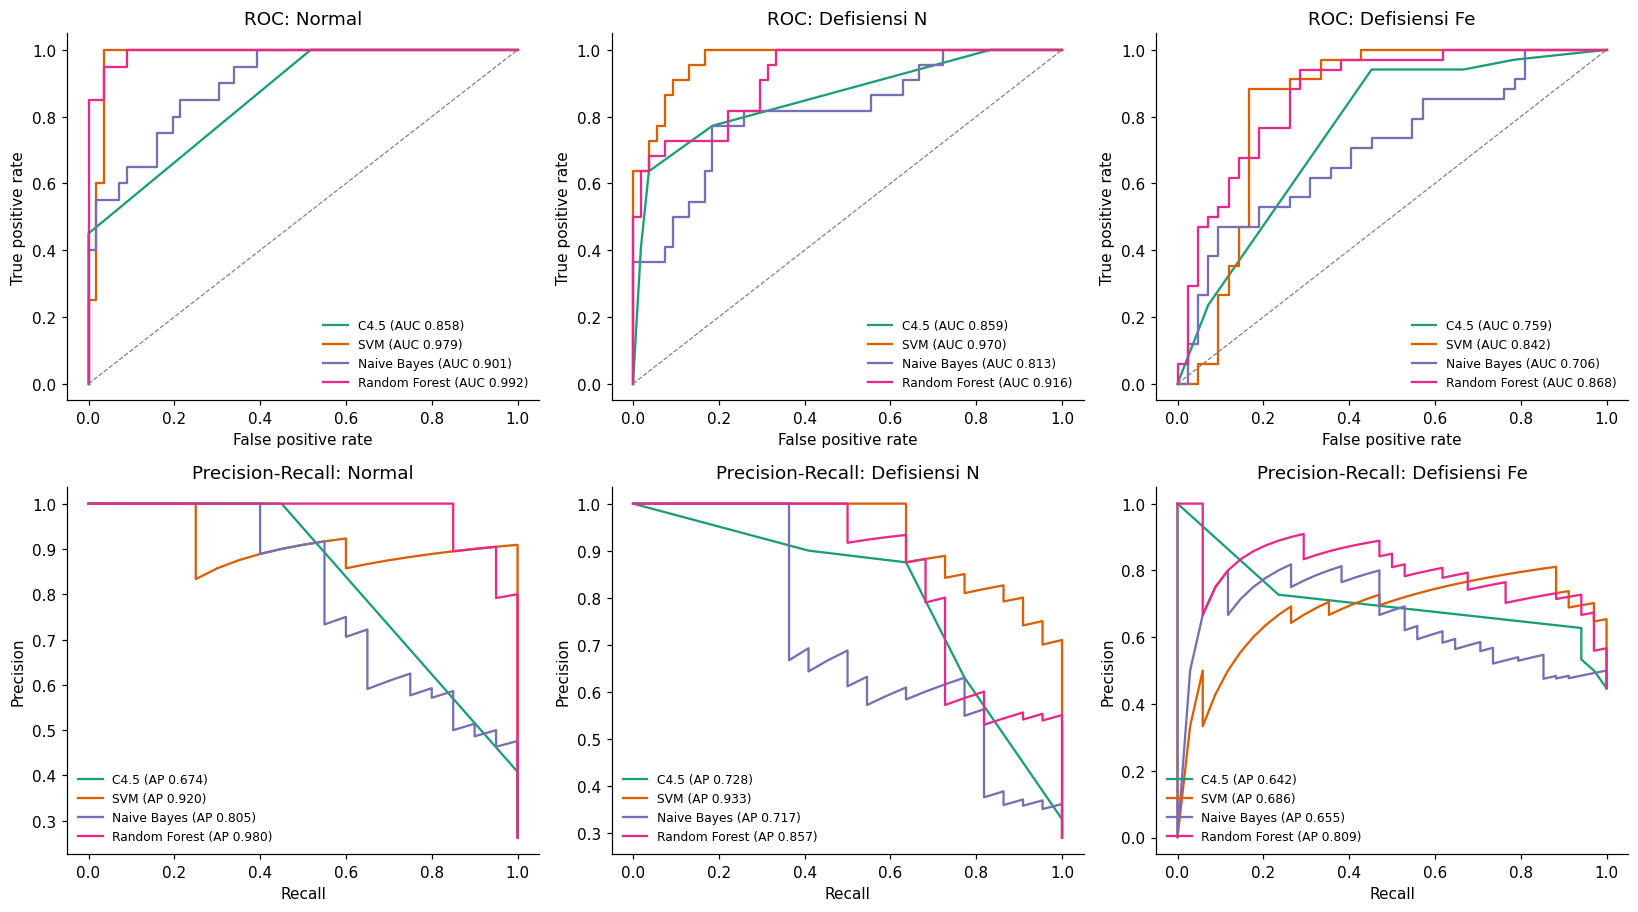

AUC                                 AP               \
kelas         Defisiensi Fe Defisiensi N  Normal Defisiensi Fe Defisiensi N   
model                                                                         
C4.5                 0.7591       0.8590  0.8576        0.6419       0.7275   
SVM                  0.8417       0.9697  0.9795        0.6858       0.9330   
Naive Bayes          0.7059       0.8131  0.9009        0.6549       0.7169   
Random Forest        0.8683       0.9158  0.9920        0.8095       0.8570   

                       
kelas          Normal  
model                  
C4.5           0.6745  
SVM            0.9196  
Naive Bayes    0.8050  
Random Forest  0.9802

In [13]:
fig, curve_table = ev.plot_model_curves(test_predictions)
save_figure(fig, "roc_pr_models.png")
plt.show()

curve_wide = curve_table.pivot(index="model", columns="kelas", values=["AUC", "AP"]).reindex(list(MODEL_NAMES))
save_table(curve_wide.round(4), "roc_pr_summary")
display(curve_wide.round(4))

##### 5.6 Interval kepercayaan bootstrap

estimate     low    high
model         metrik                                        
C4.5          F1 makro                0.7035  0.4916  0.8249
              Akurasi                 0.7237  0.5714  0.8572
              Recall Normal           0.4500  0.2308  0.6667
              Recall Defisiensi N     0.6364     NaN     NaN
              Recall Defisiensi Fe    0.9412  0.8182  1.0000
SVM           F1 makro                0.8431  0.6312  0.9515
              Akurasi                 0.8421  0.6986  0.9559
              Recall Normal           0.9500  0.8966  1.0000
              Recall Defisiensi N     0.6818     NaN     NaN
              Recall Defisiensi Fe    0.8824  0.6783  1.0000
Naive Bayes   F1 makro                0.6363  0.4723  0.7479
              Akurasi                 0.6316  0.5181  0.7657
              Recall Normal           0.8000  0.6249  0.9474
              Recall Defisiensi N     0.7273     NaN     NaN
              Recall Defisiensi Fe    0.4706  0.3438  0.6667
Random Forest F1 makro                0.8156  0.6044  0.9427
              Akurasi                 0.8158  0.6712  0.9474
              Recall Normal           0.7500  0.5938  1.0000
              Recall Defisiensi N     0.6818     NaN     NaN
              Recall Defisiensi Fe    0.9412  0.8182  1.0000

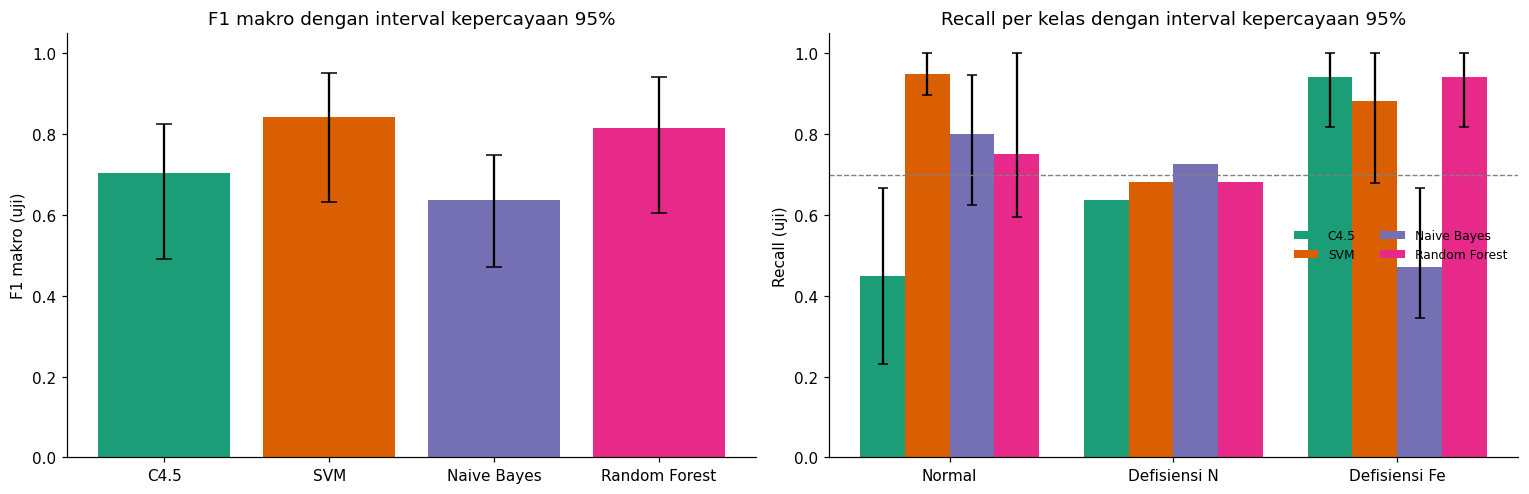

In [14]:
bootstrap_metrics = {
    "F1 makro": ev.fast_macro_f1,
    "Akurasi": ev.fast_accuracy,
    "Recall Normal": ev.fast_recall("normal"),
    "Recall Defisiensi N": ev.fast_recall("n_deficiency"),
    "Recall Defisiensi Fe": ev.fast_recall("fe_deficiency"),
}
bootstrap = {
    (name, metric_name): ev.bootstrap_group_ci(test_predictions[name], metric, n_boot=N_BOOTSTRAP, seed=SEED)
    for name in MODEL_NAMES
    for metric_name, metric in bootstrap_metrics.items()
}
bootstrap_table = pd.DataFrame(bootstrap).T[["estimate", "low", "high"]]
bootstrap_table.index.names = ["model", "metrik"]
save_table(bootstrap_table.round(4), "bootstrap_ci")
display(bootstrap_table.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
x = np.arange(len(MODEL_NAMES))
estimates = np.array([bootstrap[(n, "F1 makro")]["estimate"] for n in MODEL_NAMES])
lows = np.array([bootstrap[(n, "F1 makro")]["low"] for n in MODEL_NAMES])
highs = np.array([bootstrap[(n, "F1 makro")]["high"] for n in MODEL_NAMES])
axes[0].bar(x, estimates, yerr=[estimates - lows, highs - estimates], color=[MODEL_COLORS[n] for n in MODEL_NAMES], capsize=5)
axes[0].set_xticks(x, MODEL_NAMES)
axes[0].set(ylabel="F1 makro (uji)", title="F1 makro dengan interval kepercayaan 95%", ylim=(0, 1.05))

width = 0.2
for k, name in enumerate(MODEL_NAMES):
    values = np.array([bootstrap[(name, f"Recall {m}")]["estimate"] for m in ("Normal", "Defisiensi N", "Defisiensi Fe")])
    low = np.array([bootstrap[(name, f"Recall {m}")]["low"] for m in ("Normal", "Defisiensi N", "Defisiensi Fe")])
    high = np.array([bootstrap[(name, f"Recall {m}")]["high"] for m in ("Normal", "Defisiensi N", "Defisiensi Fe")])
    axes[1].bar(np.arange(3) + (k - 1.5) * width, values, width, yerr=[values - low, high - values], color=MODEL_COLORS[name], label=name, capsize=3)
axes[1].axhline(MIN_DEFICIENCY_RECALL, color="grey", linestyle="--", linewidth=0.9)
axes[1].set_xticks(range(3), ["Normal", "Defisiensi N", "Defisiensi Fe"])
axes[1].set(ylabel="Recall (uji)", title="Recall per kelas dengan interval kepercayaan 95%", ylim=(0, 1.05))
axes[1].legend(frameon=False, fontsize=8, ncol=2)
fig.tight_layout()
save_figure(fig, "bootstrap_ci.png")
plt.show()

##### 5.7 Selisih berpasangan terhadap C4.5

In [15]:
primary_frame = test_predictions[PRIMARY_MODEL]
paired_rows = {}
for name in MODEL_NAMES:
    if name == PRIMARY_MODEL:
        continue
    other = test_predictions[name]
    assert (other["image_id"].to_numpy() == primary_frame["image_id"].to_numpy()).all()
    paired_rows[f"{name} - {PRIMARY_MODEL}"] = ev.paired_bootstrap_difference(
        primary_frame["label"], other["pred"], primary_frame["pred"], primary_frame["source_group"], ev.fast_macro_f1, n_boot=N_BOOTSTRAP, seed=SEED
    )
paired_test = pd.DataFrame(paired_rows).T
save_table(paired_test.round(4), "paired_test_difference")
display(paired_test.round(4))

cv_scores = {}
for name in MODEL_NAMES:
    path = next(ML_DIR / p for p in results[name]["artifacts"]["oof"] if p.endswith(f"_{SELECTED_SET}.csv"))
    cv_scores[name] = ev.fold_scores(pd.read_csv(path)).set_index(["repeat", "fold"])["macro_f1"]
cv_paired = {}
for name in MODEL_NAMES:
    if name == PRIMARY_MODEL:
        continue
    difference = cv_scores[name] - cv_scores[PRIMARY_MODEL]
    cv_paired[f"{name} - {PRIMARY_MODEL}"] = {"rata-rata selisih": difference.mean(), "SD selisih": difference.std(), "min": difference.min(), "maks": difference.max(), "lipatan model lebih baik": int((difference > 0).sum()), "jumlah lipatan": len(difference)}
cv_paired_table = pd.DataFrame(cv_paired).T
save_table(cv_paired_table.round(4), "paired_cv_difference")
display(cv_paired_table.round(4))

,estimate,low,high,share_positive
SVM - C4.5,0.1396,0.0403,0.2414,0.9965
Naive Bayes - C4.5,-0.0672,-0.2286,0.1051,0.2215
Random Forest - C4.5,0.1121,0.0428,0.2277,1.0000


,rata-rata selisih,SD selisih,min,maks,lipatan model lebih baik,jumlah lipatan
SVM - C4.5,0.0635,0.0842,-0.1255,0.1950,13.0,15.0
Naive Bayes - C4.5,-0.1028,0.0751,-0.2066,0.0709,2.0,15.0
Random Forest - C4.5,0.0237,0.0701,-0.1196,0.1475,9.0,15.0


#### 6. Aturan Pemilihan Model Utama

##### 6.1 Penerapan aturan

In [16]:
test_f1 = {name: float(test_summary.loc[name, "F1 makro"]) for name in MODEL_NAMES}
best_model = max(test_f1, key=test_f1.get)
gap_to_best = test_f1[best_model] - test_f1[PRIMARY_MODEL]
recall_n = float(test_summary.loc[PRIMARY_MODEL, f"recall {CLASS_LABEL_ID['n_deficiency']}"])
recall_fe = float(test_summary.loc[PRIMARY_MODEL, f"recall {CLASS_LABEL_ID['fe_deficiency']}"])

rule_table = pd.DataFrame(
    [
        {"syarat": f"Selisih F1 makro terhadap model terbaik ({best_model}) <= {MACRO_F1_MARGIN}", "nilai": round(gap_to_best, 4), "terpenuhi": gap_to_best <= MACRO_F1_MARGIN},
        {"syarat": f"Recall Defisiensi N >= {MIN_DEFICIENCY_RECALL}", "nilai": round(recall_n, 4), "terpenuhi": recall_n >= MIN_DEFICIENCY_RECALL},
        {"syarat": f"Recall Defisiensi Fe >= {MIN_DEFICIENCY_RECALL}", "nilai": round(recall_fe, 4), "terpenuhi": recall_fe >= MIN_DEFICIENCY_RECALL},
    ]
).set_index("syarat")
RULE_PASSED = bool(rule_table["terpenuhi"].all())
save_table(rule_table, "selection_rule")
display(rule_table)

print("Model utama yang dievaluasi :", PRIMARY_MODEL)
print("Seluruh syarat terpenuhi    :", RULE_PASSED)
print("Ambang dikonfirmasi dosen   :", THRESHOLDS_CONFIRMED_WITH_SUPERVISOR)
if not RULE_PASSED:
    print("Hasil dicatat apa adanya: keputusan mengganti model dibahas dengan dosen pembimbing dan dicatat di ADR.")

,nilai,terpenuhi
syarat,,
Selisih F1 makro terhadap model terbaik (SVM) <= 0.05,0.1396,False
Recall Defisiensi N >= 0.7,0.6364,False
Recall Defisiensi Fe >= 0.7,0.9412,True


Model utama yang dievaluasi : C4.5
Seluruh syarat terpenuhi    : False
Ambang dikonfirmasi dosen   : False
Hasil dicatat apa adanya: keputusan mengganti model dibahas dengan dosen pembimbing dan dicatat di ADR.


#### 7. Analisis Kesalahan pada Data Uji

##### 7.1 Pasangan kesalahan setiap model

In [17]:
error_rows = []
for name, frame in test_predictions.items():
    wrong = frame[frame["label"] != frame["pred"]]
    for (true_label, predicted), count in wrong.groupby(["label", "pred"]).size().items():
        error_rows.append({"model": name, "sebenarnya": CLASS_LABEL_ID[true_label], "prediksi": CLASS_LABEL_ID[predicted], "jumlah": int(count)})
error_table = pd.DataFrame(error_rows, columns=["model", "sebenarnya", "prediksi", "jumlah"])
save_table(error_table, "error_pairs", index=False)
display(error_table.pivot_table(index=["sebenarnya", "prediksi"], columns="model", values="jumlah", fill_value=0).reindex(columns=list(MODEL_NAMES), fill_value=0))

model                        C4.5  SVM  Naive Bayes  Random Forest
sebenarnya    prediksi                                            
Defisiensi Fe Defisiensi N    2.0  2.0         10.0            2.0
              Normal          0.0  2.0          8.0            0.0
Defisiensi N  Defisiensi Fe   8.0  7.0          3.0            7.0
              Normal          0.0  0.0          3.0            0.0
Normal        Defisiensi Fe  11.0  1.0          4.0            5.0

##### 7.2 Galeri salah klasifikasi model utama

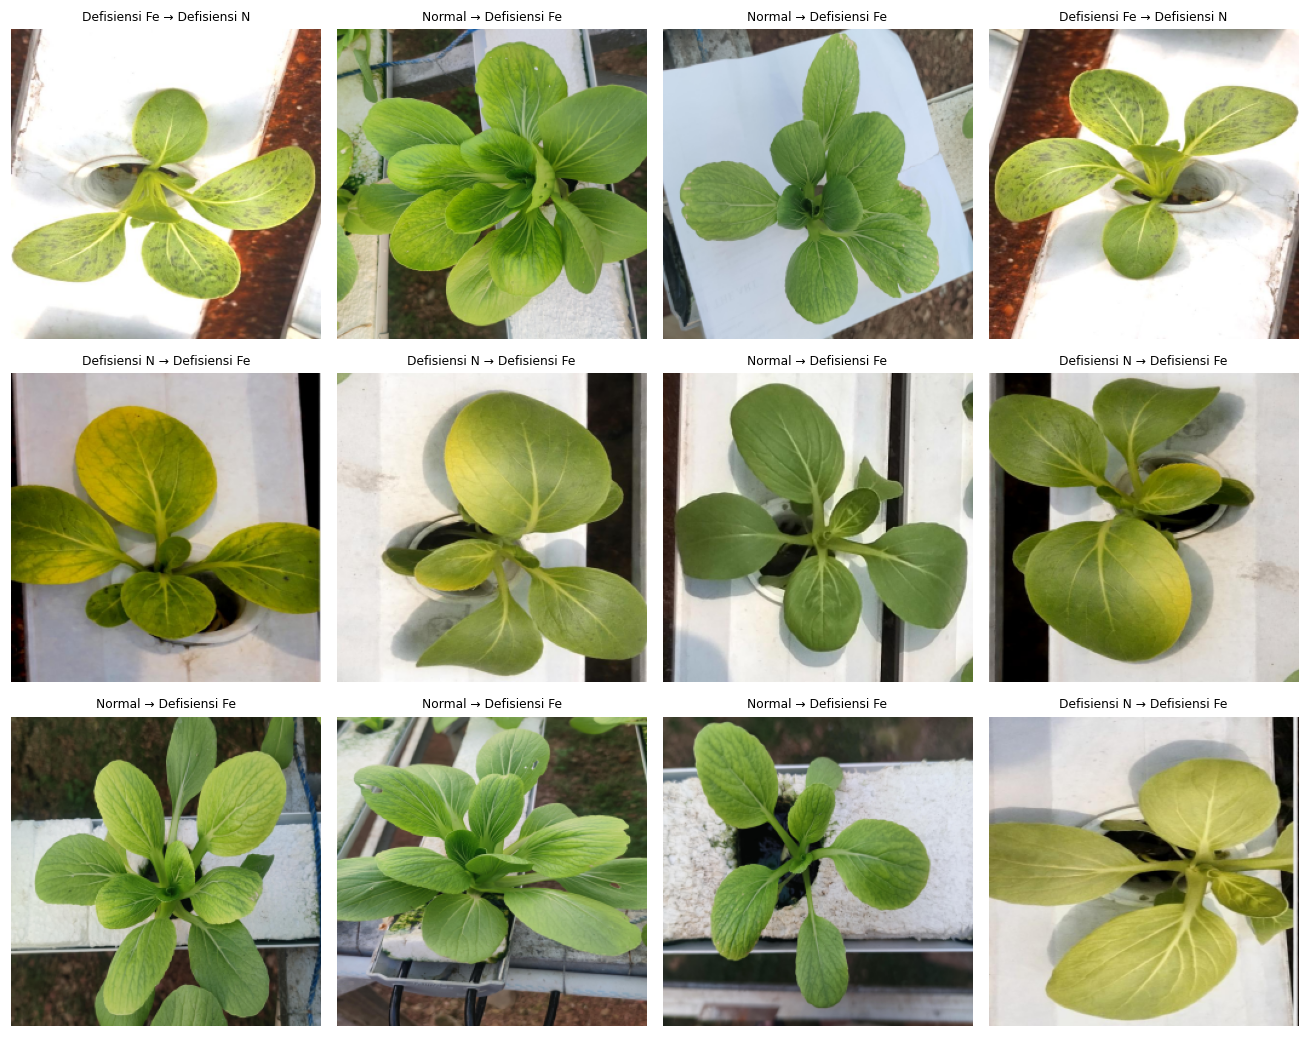

Salah klasifikasi C4.5 : 21 dari 76 berkas uji


In [18]:
errors = primary_frame[primary_frame["label"] != primary_frame["pred"]]
fig = ev.plot_gallery(errors, RAW_DIR, max_items=GALLERY_SIZE, seed=SEED)
save_figure(fig, "misclassified_gallery.png")
plt.show()
print("Salah klasifikasi", PRIMARY_MODEL, ":", len(errors), "dari", len(primary_frame), "berkas uji")

##### 7.3 Kesepakatan antar model

,C4.5,SVM,Naive Bayes,Random Forest
C4.5,1.0000,0.8289,0.6053,0.9079
SVM,0.8289,1.0000,0.6184,0.9211
Naive Bayes,0.6053,0.6184,1.0000,0.6711
Random Forest,0.9079,0.9211,0.6711,1.0000


Benar pada keempat model : 36 berkas
Salah pada keempat model : 7 berkas


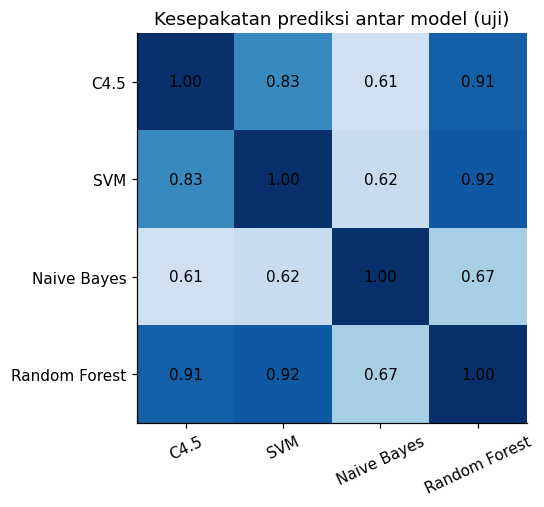

In [19]:
prediction_matrix = pd.DataFrame({name: test_predictions[name]["pred"].to_numpy() for name in MODEL_NAMES})
correct_matrix = pd.DataFrame({name: (test_predictions[name]["pred"] == test_predictions[name]["label"]).to_numpy() for name in MODEL_NAMES})

agreement = pd.DataFrame(index=MODEL_NAMES, columns=MODEL_NAMES, dtype=float)
for a in MODEL_NAMES:
    for b in MODEL_NAMES:
        agreement.loc[a, b] = float((prediction_matrix[a] == prediction_matrix[b]).mean())
save_table(agreement.round(4), "model_agreement")
display(agreement.round(4))

all_correct = int(correct_matrix.all(axis=1).sum())
all_wrong = int((~correct_matrix).all(axis=1).sum())
print(f"Benar pada keempat model : {all_correct} berkas")
print(f"Salah pada keempat model : {all_wrong} berkas")

fig, ax = plt.subplots(figsize=(5.5, 4.6))
ax.imshow(agreement.to_numpy(dtype=float), cmap="Blues", vmin=0.5, vmax=1)
ax.set_xticks(range(4), MODEL_NAMES, rotation=25)
ax.set_yticks(range(4), MODEL_NAMES)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{agreement.iloc[i, j]:.2f}", ha="center", va="center")
ax.set_title("Kesepakatan prediksi antar model (uji)")
save_figure(fig, "model_agreement.png")
plt.show()

#### 8. Pemeriksaan pada Foto Primer (Eksternal)

##### 8.1 Prediksi setiap model

In [20]:
external_predictions = {name: predict_frame(fitted[name], external) for name in MODEL_NAMES}
external_table = external_predictions[PRIMARY_MODEL][["image_id", "label"]].copy()
for name in MODEL_NAMES:
    external_table[name] = external_predictions[name]["pred"].map(CLASS_LABEL_ID)
external_table["label"] = external_table["label"].map(CLASS_LABEL_ID)
save_table(external_table, "external_predictions", index=False)
display(external_table)

external_accuracy = pd.Series({name: float((external_predictions[name]["pred"] == external_predictions[name]["label"]).mean()) for name in MODEL_NAMES}, name="akurasi")
save_table(external_accuracy.round(4).to_frame(), "external_accuracy")
display(external_accuracy.round(4).to_frame())

,image_id,label,C4.5,SVM,Naive Bayes,Random Forest
0,primer1.jpeg,Normal,Defisiensi Fe,Defisiensi Fe,Normal,Defisiensi Fe
1,primer2.jpeg,Normal,Defisiensi Fe,Defisiensi Fe,Normal,Defisiensi Fe
2,primer3.jpeg,Normal,Defisiensi Fe,Defisiensi Fe,Normal,Defisiensi Fe
3,primer4.jpeg,Normal,Defisiensi Fe,Defisiensi Fe,Normal,Defisiensi Fe
4,primer5.jpeg,Normal,Defisiensi Fe,Defisiensi Fe,Normal,Defisiensi Fe
5,primer6.jpeg,Normal,Defisiensi Fe,Defisiensi Fe,Normal,Defisiensi Fe
6,primer7.jpeg,Normal,Defisiensi Fe,Defisiensi Fe,Normal,Defisiensi Fe
7,primer8.jpeg,Normal,Defisiensi Fe,Defisiensi Fe,Normal,Defisiensi Fe


,akurasi
C4.5,0.0
SVM,0.0
Naive Bayes,1.0
Random Forest,0.0


#### 9. Perbandingan Himpunan Fitur dan Waktu Komputasi

##### 9.1 Himpunan fitur A1 dan A2 (validasi silang)

F1 makro validasi              SD        
himpunan                     A1      A2      A1      A2
model                                                  
C4.5                     0.6988  0.7307  0.0804  0.1118
SVM                      0.7623  0.7656  0.0926  0.0927
Naive Bayes              0.5960  0.6853  0.0621  0.0843
Random Forest            0.7225  0.7589  0.0864  0.1096

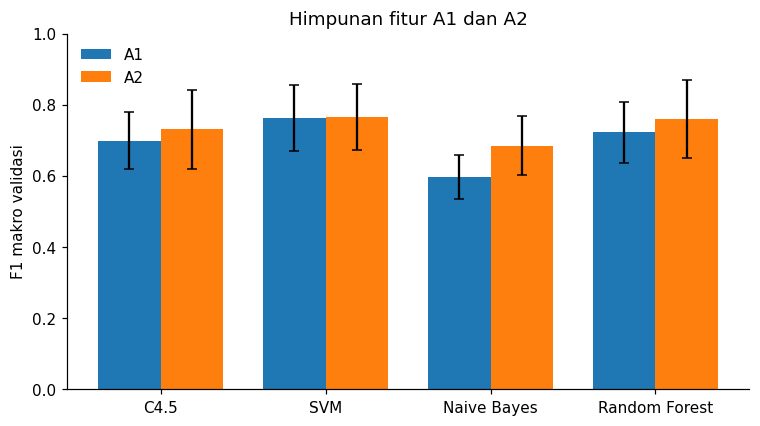

In [21]:
feature_set_rows = []
for name in MODEL_NAMES:
    for set_name, entry in results[name]["best_config"].items():
        feature_set_rows.append({"model": name, "himpunan": set_name, "F1 makro validasi": entry["val_macro_f1_mean"], "SD": entry["val_macro_f1_sd"]})
feature_set_table = pd.DataFrame(feature_set_rows)
save_table(feature_set_table.round(4), "feature_set_comparison", index=False)
display(feature_set_table.pivot(index="model", columns="himpunan", values=["F1 makro validasi", "SD"]).reindex(list(MODEL_NAMES)).round(4))

fig, ax = plt.subplots(figsize=(8, 4.2))
width = 0.38
for k, set_name in enumerate(("A1", "A2")):
    subset = feature_set_table[feature_set_table["himpunan"] == set_name].set_index("model").reindex(list(MODEL_NAMES))
    ax.bar(np.arange(len(MODEL_NAMES)) + (k - 0.5) * width, subset["F1 makro validasi"], width, yerr=subset["SD"], capsize=3, label=set_name)
ax.set_xticks(range(len(MODEL_NAMES)), MODEL_NAMES)
ax.set(ylabel="F1 makro validasi", title="Himpunan fitur A1 dan A2", ylim=(0, 1))
ax.legend(frameon=False)
save_figure(fig, "feature_set_comparison.png")
plt.show()

##### 9.2 Waktu komputasi

,pelatihan model akhir (detik),penalaan A1 (detik),penalaan A2 (detik),prediksi per sampel (ms),pelatihan ulang notebook ini (detik),praproses per citra (ms),total per citra (ms)
C4.5,0.0049,12.7508,7.4812,0.0009,0.0086,7.935,7.9359
SVM,0.0052,6.0661,10.7193,0.1120,0.0079,7.935,8.0470
Naive Bayes,0.0018,0.1855,0.1934,0.0719,0.0021,7.935,8.0069
Random Forest,0.3939,161.7308,132.6602,8.3672,0.4337,7.935,16.3022


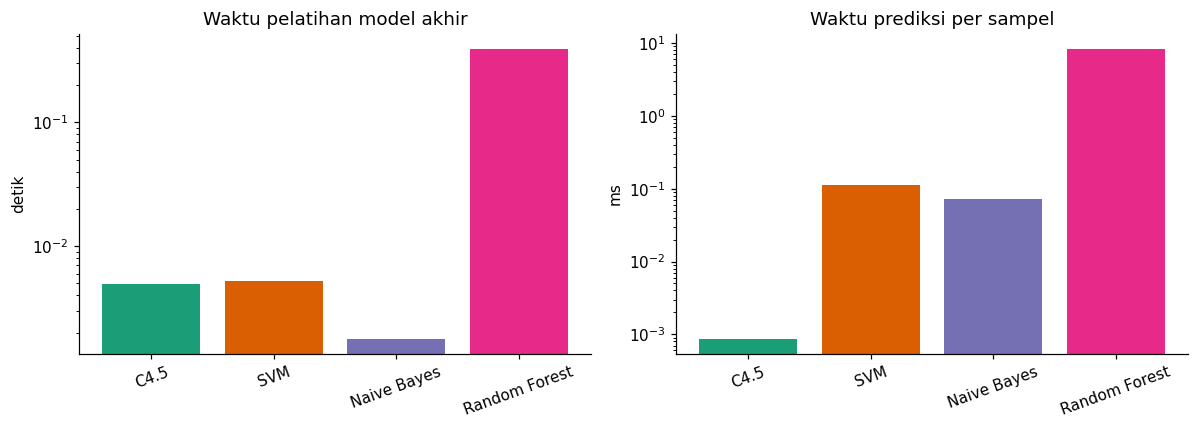

In [22]:
def predict_ms(name):
    compute = results[name]["compute"]
    return compute["predict_ms_per_sample_json"] if name == "C4.5" else compute["predict_ms_per_sample"]


compute_table = pd.DataFrame(
    {
        name: {
            "pelatihan model akhir (detik)": results[name]["compute"]["final_train_seconds"]["mean"],
            "penalaan A1 (detik)": results[name]["compute"]["tuning_seconds"]["A1"],
            "penalaan A2 (detik)": results[name]["compute"]["tuning_seconds"]["A2"],
            "prediksi per sampel (ms)": predict_ms(name)["mean_ms"],
            "pelatihan ulang notebook ini (detik)": fit_seconds[name],
        }
        for name in MODEL_NAMES
    }
).T
preprocessing_timing = pd.read_csv(TABLES_DIR / "01_timing_per_stage.csv", index_col=0)
PREPROCESSING_MS = float(preprocessing_timing.loc["total (tanpa baca berkas)", "rata-rata (ms)"])
compute_table["praproses per citra (ms)"] = PREPROCESSING_MS
compute_table["total per citra (ms)"] = compute_table["praproses per citra (ms)"] + compute_table["prediksi per sampel (ms)"]
save_table(compute_table.round(4), "compute_comparison")
display(compute_table.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(MODEL_NAMES, compute_table["pelatihan model akhir (detik)"], color=[MODEL_COLORS[n] for n in MODEL_NAMES])
axes[0].set(ylabel="detik", title="Waktu pelatihan model akhir", yscale="log")
axes[1].bar(MODEL_NAMES, compute_table["prediksi per sampel (ms)"], color=[MODEL_COLORS[n] for n in MODEL_NAMES])
axes[1].set(ylabel="ms", title="Waktu prediksi per sampel", yscale="log")
for ax in axes:
    ax.tick_params(axis="x", rotation=20)
fig.tight_layout()
save_figure(fig, "compute_comparison.png")
plt.show()

#### 10. Registry dan Artefak Model

##### 10.1 Penyimpanan artefak

In [23]:
VERSIONS = {name: f"{MODEL_IDS[name]}-{MODEL_VERSION}" for name in MODEL_NAMES}
ARTIFACT_FILES = {}

tree_payload = fitted["C4.5"].to_dict(
    version=VERSIONS["C4.5"],
    extra={
        "feature_set": SELECTED_SET,
        "class_weight": locked["C4.5"]["class_weight"],
        "trained_rows": int(len(train)),
        "trained_groups": int(train["source_group"].nunique()),
        "seed": SEED,
        "created_at": datetime.now().isoformat(timespec="seconds"),
    },
)
ARTIFACT_FILES["C4.5"] = f"{VERSIONS['C4.5']}.json"
(MODELS_DIR / ARTIFACT_FILES["C4.5"]).write_text(json.dumps(tree_payload, indent=2), encoding="utf-8")

for name in MODEL_NAMES:
    if name == "C4.5":
        continue
    ARTIFACT_FILES[name] = f"{VERSIONS[name]}.joblib"
    joblib.dump(fitted[name].estimator, MODELS_DIR / ARTIFACT_FILES[name])

artifact_table = pd.DataFrame(
    {"berkas": ARTIFACT_FILES, "ukuran (byte)": {name: (MODELS_DIR / file).stat().st_size for name, file in ARTIFACT_FILES.items()}}
)
save_table(artifact_table, "artifacts")
display(artifact_table)

,berkas,ukuran (byte)
C4.5,c45-0.1.0.json,3227
SVM,svm-0.1.0.joblib,12050
Naive Bayes,naive-bayes-0.1.0.joblib,1087
Random Forest,random-forest-0.1.0.joblib,2004049


##### 10.2 registry.json

In [24]:
preprocessing_params = json.loads((PROCESSED_DIR / "preprocessing_params.json").read_text(encoding="utf-8"))
preprocessing_block = registry.preprocessing_entry(preprocessing_params["pipeline"])
dataset_block = {
    "origin": "roboflow",
    "rows": int(len(train)),
    "source_groups": int(train["source_group"].nunique()),
    "test_rows": int(len(test)),
    "test_source_groups": int(test["source_group"].nunique()),
    "seed": SEED,
}
trained_at = datetime.now().isoformat(timespec="seconds")

entries = []
for name in MODEL_NAMES:
    table = ev.metrics_table(test_predictions[name]["label"], test_predictions[name]["pred"])
    per_class = {c: {"precision": float(table.loc[CLASS_LABEL_ID[c], "precision"]), "recall": float(table.loc[CLASS_LABEL_ID[c], "recall"]), "f1": float(table.loc[CLASS_LABEL_ID[c], "f1"])} for c in CLASSES}
    entries.append(
        registry.build_entry(
            version=VERSIONS[name],
            algorithm=MODEL_IDS[name],
            role="primary" if name == PRIMARY_MODEL else "comparator",
            artifact=ARTIFACT_FILES[name],
            features=FEATURES,
            classes=list(CLASSES),
            preprocessing=preprocessing_block,
            dataset=dataset_block,
            compute={
                "cpu": HARDWARE["CPU"],
                "train_seconds": float(results[name]["compute"]["final_train_seconds"]["mean"]),
                "predict_ms_per_sample": float(predict_ms(name)["mean_ms"]),
            },
            metrics=registry.metrics_entry(float(test_summary.loc[name, "akurasi"]), float(test_summary.loc[name, "F1 makro"]), per_class),
            trained_at=trained_at,
            extra={
                "parameters": locked[name]["params"],
                "feature_set": SELECTED_SET,
                "cv_macro_f1": float(results[name]["selected"]["oof_metrics"]["macro_f1_fold_mean"]),
                "libraries": {"scikit_learn": sklearn.__version__, "numpy": np.__version__},
            },
        )
    )

registry_data = registry.build_registry(
    active_version=VERSIONS[PRIMARY_MODEL],
    entries=entries,
    extra={
        "selection": {
            "rule": "ML.md 8.1",
            "macro_f1_margin": MACRO_F1_MARGIN,
            "min_deficiency_recall": MIN_DEFICIENCY_RECALL,
            "thresholds_confirmed_with_supervisor": THRESHOLDS_CONFIRMED_WITH_SUPERVISOR,
            "best_model_by_test_macro_f1": best_model,
            "gap_to_best": round(gap_to_best, 4),
            "all_conditions_met": RULE_PASSED,
        }
    },
)
problems = registry.validate_registry(registry_data, MODELS_DIR)
print("Masalah registry :", problems if problems else "tidak ada")
assert not problems
registry.save_registry(MODELS_DIR / "registry.json", registry_data)
print("Disimpan :", MODELS_DIR / "registry.json")
print("Versi aktif :", registry_data["active_version"])

Masalah registry : tidak ada
Disimpan : D:\LARAGON\www\nutrify\ml\models\registry.json
Versi aktif : c45-0.1.0


##### 10.3 Pembacaan ulang registry dan prediksi dari JSON

In [25]:
reloaded = registry.load_registry(MODELS_DIR / "registry.json")
active = next(m for m in reloaded["models"] if m["version"] == reloaded["active_version"])
tree_json = json.loads((MODELS_DIR / active["artifact"]).read_text(encoding="utf-8"))

from_json = np.array([c45.predict_from_dict(tree_json, dict(zip(FEATURES, row)))["predicted_class"] for row in test[FEATURES].to_numpy(dtype=float)])
assert (from_json == primary_frame["pred"].to_numpy()).all()
print("Model aktif                         :", active["version"], "| fitur:", active["features"])
print("Prediksi JSON sama dengan model uji :", True)
print("Contoh jalur aturan                  :", c45.predict_from_dict(tree_json, dict(zip(FEATURES, test[FEATURES].iloc[0])))["rule_path"])

Model aktif                         : c45-0.1.0 | fitur: ['Mean_R', 'Mean_G', 'Mean_B']
Prediksi JSON sama dengan model uji : True
Contoh jalur aturan                  : [{'feature': 'Mean_R', 'operator': '<=', 'threshold': 144.55}, {'feature': 'Mean_R', 'operator': '>', 'threshold': 95.75}]


#### 11. Ringkasan Akhir

##### 11.1 results JSON dan tabel ringkasan

In [26]:
comparison_results = {
    "created_at": datetime.now().isoformat(timespec="seconds"),
    "seed": SEED,
    "libraries": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__, "scikit_learn": sklearn.__version__},
    "hardware": HARDWARE,
    "feature_set": SELECTED_SET,
    "features": FEATURES,
    "test": {"rows": int(len(test)), "source_groups": int(test["source_group"].nunique())},
    "test_summary": test_summary.round(6).to_dict(orient="index"),
    "bootstrap_95ci": {f"{m}|{k}": {kk: float(vv) for kk, vv in v.items() if kk in ("estimate", "low", "high")} for (m, k), v in bootstrap.items()},
    "paired_test_difference": {k: {kk: float(vv) for kk, vv in v.items()} for k, v in paired_rows.items()},
    "selection_rule": {
        "primary": PRIMARY_MODEL,
        "best_model": best_model,
        "gap_to_best": float(gap_to_best),
        "recall_n": recall_n,
        "recall_fe": recall_fe,
        "margin": MACRO_F1_MARGIN,
        "min_recall": MIN_DEFICIENCY_RECALL,
        "all_conditions_met": RULE_PASSED,
        "thresholds_confirmed_with_supervisor": THRESHOLDS_CONFIRMED_WITH_SUPERVISOR,
    },
    "external_accuracy": external_accuracy.to_dict(),
    "active_version": registry_data["active_version"],
}
(RESULTS_DIR / "07_comparison_results.json").write_text(json.dumps(comparison_results, indent=2, default=str), encoding="utf-8")

final_summary = pd.DataFrame(
    [
        ("Himpunan fitur", SELECTED_SET),
        ("Berkas uji / foto sumber uji", f"{len(test)} / {test['source_group'].nunique()}"),
        *[(f"F1 makro uji, {name}", round(test_f1[name], 4)) for name in MODEL_NAMES],
        ("Model terbaik (F1 makro uji)", best_model),
        ("Selisih C4.5 terhadap terbaik", round(gap_to_best, 4)),
        ("Recall Defisiensi N, C4.5", round(recall_n, 4)),
        ("Recall Defisiensi Fe, C4.5", round(recall_fe, 4)),
        ("Seluruh syarat 8.1 terpenuhi", RULE_PASSED),
        ("Versi aktif di registry", registry_data["active_version"]),
    ],
    columns=["item", "nilai"],
)
save_table(final_summary, "final_summary", index=False)
display(final_summary)

,item,nilai
0,Himpunan fitur,A1
1,Berkas uji / foto sumber uji,76 / 28
2,"F1 makro uji, C4.5",0.7035
3,"F1 makro uji, SVM",0.8431
4,"F1 makro uji, Naive Bayes",0.6363
5,"F1 makro uji, Random Forest",0.8156
6,Model terbaik (F1 makro uji),SVM
7,Selisih C4.5 terhadap terbaik,0.1396
8,"Recall Defisiensi N, C4.5",0.6364
9,"Recall Defisiensi Fe, C4.5",0.9412
